In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

burgundy_palette = ["#6D213C", "#A64D68", "#D99AAA", "#E8BBC6", "#F4DDE3"]

sns.set_theme(
    style="whitegrid",
    palette=burgundy_palette,
    rc={
        "figure.figsize": (10, 5),
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "grid.alpha": 0.2,
        "axes.spines.top": False,
        "axes.spines.right": False
    }
)

plt.rcParams["axes.prop_cycle"] = plt.cycler(color=burgundy_palette)

df = pd.read_csv("Financial_10_17_2026.csv", low_memory=False)
df.shape

(4388, 161)

In [3]:
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isna().sum().sum())
print("Fully empty columns:", df.isna().all().sum())

Shape: (4388, 161)
Duplicate rows: 0
Missing values: 88885
Fully empty columns: 8


In [4]:
missing = (df.isna().mean().mul(100).sort_values(ascending=False))
display(missing[missing > 0].head(15))

P3LTOT      100.000000
P9LTOT      100.000000
NALTOT      100.000000
MSA_NAME    100.000000
LSAORE      100.000000
LSALNLS     100.000000
LSASCDBT    100.000000
LSAOA       100.000000
LNNDEPC      98.313582
SZLNCRCD     98.108478
SZLNCON      98.108478
DEPFOR       98.108478
SZLNCI       98.108478
SZLNHEL      98.108478
SZLAUTO      98.108478
dtype: float64

In [5]:
financial_cols = ["ASSET", "DEP", "NETINC","ROA", "ROE", "NIMY", "LNLSDEPR", "RBCRWAJ"]
df[financial_cols].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
ASSET,4388.0,5748593.65,84255495.41,3235.00,162485.00,370839.50,958334.00,3.813431e+09
DEP,4388.0,4516025.04,62854017.44,0.00,137353.75,316487.00,803266.75,2.649438e+09
NETINC,4379.0,49897.56,782704.59,-445862.00,1028.50,2980.00,8017.50,3.822700e+07
ROA,4388.0,1.30,7.86,-27.83,0.71,1.10,1.54,5.030500e+02
ROE,4377.0,10.13,78.66,-4772.18,6.90,10.96,15.27,1.728630e+03
NIMY,4388.0,3.80,2.33,-0.85,3.17,3.67,4.23,1.350500e+02
LNLSDEPR,4388.0,77.34,23.17,0.00,65.47,79.76,90.97,5.314600e+02
RBCRWAJ,4388.0,12.46,24.00,0.00,0.00,12.93,16.53,5.084300e+02


In [6]:
empty_cols = df.columns[df.isna().all()].tolist()
constant_cols = df.columns[df.nunique(dropna=True) <= 1].tolist()
print("Empty columns:", empty_cols)
print("Constant columns:", constant_cols)

Empty columns: ['P9LTOT', 'MSA_NAME', 'NALTOT', 'LSAORE', 'LSALNLS', 'P3LTOT', 'LSAOA', 'LSASCDBT']
Constant columns: ['P9LTOT', 'MSA_NAME', 'NALTOT', 'INSAGNT1', 'LSAORE', 'LSALNLS', 'P3LTOT', 'RISDATE', 'HCTMULT', 'SZLNCRCD', 'LSAOA', 'ACTIVE', 'REPDTE', 'LSASCDBT']


In [7]:
df = df.drop(columns=empty_cols)
print("Shape after cleaning:", df.shape)

Shape after cleaning: (4388, 153)


In [8]:
financial_cols = [ "ASSET", "DEP", "NETINC","ROA", "ROE", "NIMY", "LNLSDEPR", "RBCRWAJ"]
df[financial_cols].isna().sum()

ASSET        0
DEP          0
NETINC       9
ROA          0
ROE         11
NIMY         0
LNLSDEPR     0
RBCRWAJ      0
dtype: int64

In [9]:
df[financial_cols].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2).T

,count,mean,std,min,1%,5%,50%,95%,99%,max
ASSET,4388.0,5748593.65,84255495.41,3235.00,23960.07,53837.85,370839.50,7132974.70,61678467.30,3.813431e+09
DEP,4388.0,4516025.04,62854017.44,0.00,13918.65,42958.70,316487.00,5781004.80,51692503.38,2.649438e+09
NETINC,4379.0,49897.56,782704.59,-445862.00,-4014.06,-28.00,2980.00,59453.30,534567.34,3.822700e+07
ROA,4388.0,1.30,7.86,-27.83,-2.12,-0.03,1.10,2.40,4.12,5.030500e+02
ROE,4377.0,10.13,78.66,-4772.18,-16.84,-0.20,10.96,23.52,38.75,1.728630e+03
NIMY,4388.0,3.80,2.33,-0.85,1.54,2.37,3.67,5.29,6.96,1.350500e+02
LNLSDEPR,4388.0,77.34,23.17,0.00,6.64,39.26,79.76,107.20,125.71,5.314600e+02
RBCRWAJ,4388.0,12.46,24.00,0.00,0.00,0.00,12.93,29.23,62.01,5.084300e+02


In [10]:
extreme = df[(df["ROA"].abs() > 10) |(df["ROE"].abs() > 100)]

display(extreme[["NAME", "ASSET", "ROA", "ROE", "NETINC"]].sort_values("ROE", ascending=False))

,NAME,ASSET,ROA,ROE,NETINC
3686,FDS BANK,70140,503.053357,1728.63,352808.0
2409,BANK OF TIOGA,415371,0.689735,430.27,2213.0
448,TITAN BANK N A,843527,25.319998,183.89,126676.0
3861,CAPITAL BANK&TRUST CO,223566,65.034557,94.56,89473.0
3018,CREDIT ONE BANK NA,1920579,29.990987,92.21,411574.0
2571,BOSTON TRUST WALDEN CO,93320,41.585113,67.50,26818.0
3791,NATIONWIDE TRUST CO FSB,177153,19.805574,54.25,25406.0
3942,NORTHWESTERN MUTUAL WEALTH M,587491,33.508320,51.23,128977.0
4296,SQUARE FINL SERVICES INC,1354373,29.092559,46.25,243205.0
3887,SEI PRIVATE TRUST CO,250341,41.509085,44.54,85508.0


In [11]:
profitability_cols = ["ROA", "ROE", "NIMY"]
profitability = df[profitability_cols].agg(["count", "mean", "median", "std", "min", "max"]).T

display(profitability.round(2))

,count,mean,median,std,min,max
ROA,4388.0,1.30,1.10,7.86,-27.83,503.05
ROE,4377.0,10.13,10.96,78.66,-4772.18,1728.63
NIMY,4388.0,3.80,3.67,2.33,-0.85,135.05


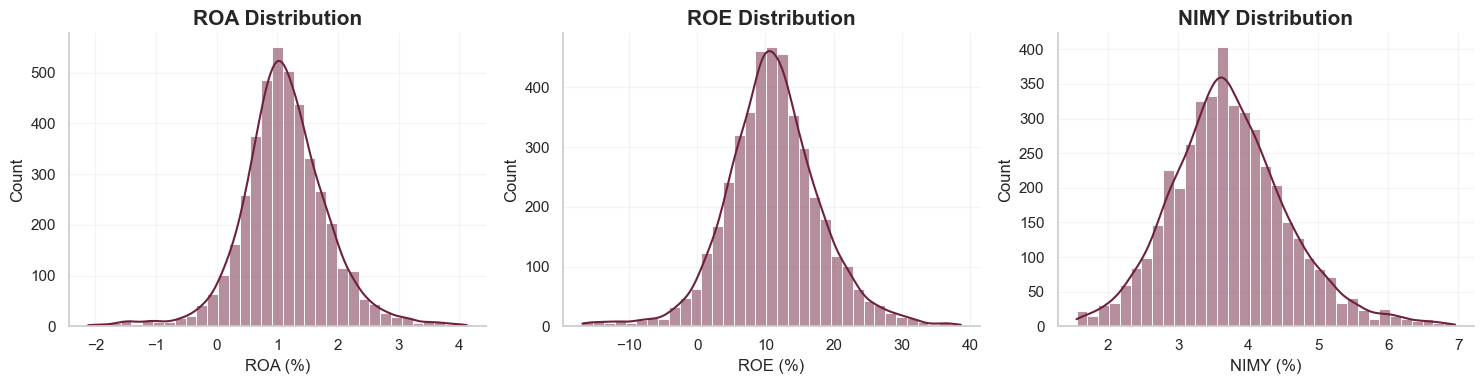

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, profitability_cols):
    values = df[col].dropna()
    lower, upper = values.quantile([0.01, 0.99])
    sns.histplot(values[values.between(lower, upper)],bins=35,kde=True,ax=ax)
    ax.set_title(f"{col} Distribution")
    ax.set_xlabel(f"{col} (%)")

plt.tight_layout()
plt.show()

In [13]:
df["profit_status"] = np.where(df["ROA"].isna(),"Missing",np.where(df["ROA"] < 0, "Unprofitable", "Profitable"))
profit_counts = df["profit_status"].value_counts()

display(profit_counts)

profit_status
Profitable      4161
Unprofitable     227
Name: count, dtype: int64

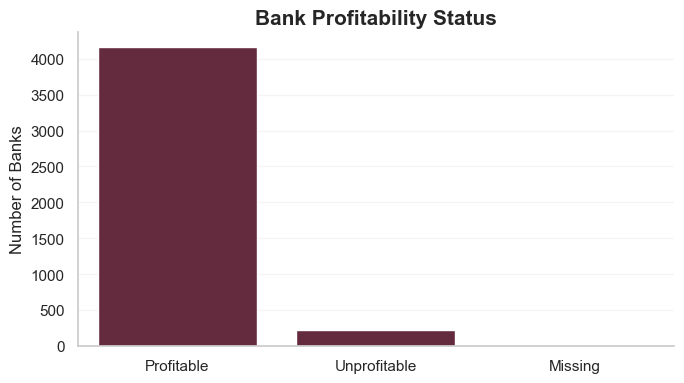

In [14]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df,x="profit_status",order=["Profitable", "Unprofitable", "Missing"])

plt.title("Bank Profitability Status")
plt.xlabel("")
plt.ylabel("Number of Banks")
plt.tight_layout()
plt.show()

In [15]:
large_banks = df[df["ASSET"] >= 1_000_000].copy()
top_roa = (large_banks.sort_values("ROA", ascending=False).head(10))

display(top_roa[["NAME", "STNAME", "ASSET", "ROA", "ROE", "NIMY"]].round(2))

,NAME,STNAME,ASSET,ROA,ROE,NIMY
3018,CREDIT ONE BANK NA,NEVADA,1920579,29.99,92.21,24.25
4296,SQUARE FINL SERVICES INC,UTAH,1354373,29.09,46.25,22.17
2937,BANK OF NY MELLON TR CO NA,CALIFORNIA,1337285,16.54,20.65,4.54
4140,COLUMN NATIONAL ASSN,CALIFORNIA,1169451,7.80,90.08,10.86
3168,COMENITY BANK,DELAWARE,7308385,5.49,38.53,21.88
877,SUTTON BANK,OHIO,1657159,5.18,40.07,5.89
3685,CAPITAL COMMUNITY BANK,UTAH,1339198,4.99,35.96,16.83
3789,WEX BANK,UTAH,8438668,4.66,57.54,10.14
3747,WEBBANK,UTAH,2387965,4.52,24.79,17.02
3924,SERVBANK NATIONAL ASSN,ILLINOIS,1075270,4.28,21.00,5.44


In [16]:
df["ASSETS_B"] = df["ASSET"] / 1_000_000
df["BANK_SIZE"] = pd.cut(
    df["ASSETS_B"],
    bins=[0, 1, 10, 100, np.inf],
    labels=["<$1B", "$1B–$10B", "$10B–$100B", ">$100B"])

df["BANK_SIZE"].value_counts().sort_index()

BANK_SIZE
<$1B          3331
$1B–$10B       900
$10B–$100B     127
>$100B          30
Name: count, dtype: int64

In [17]:
size_analysis = (df.groupby("BANK_SIZE", observed=True).agg(
        Banks=("CERT", "count"),
        Median_ROA=("ROA", "median"),
        Median_ROE=("ROE", "median"),
        Median_NIM=("NIMY", "median")).round(2))

display(size_analysis)

,Banks,Median_ROA,Median_ROE,Median_NIM
BANK_SIZE,,,,
<$1B,3331,1.10,10.94,3.75
$1B–$10B,900,1.10,11.18,3.55
$10B–$100B,127,1.06,9.54,3.36
>$100B,30,1.14,11.72,3.04


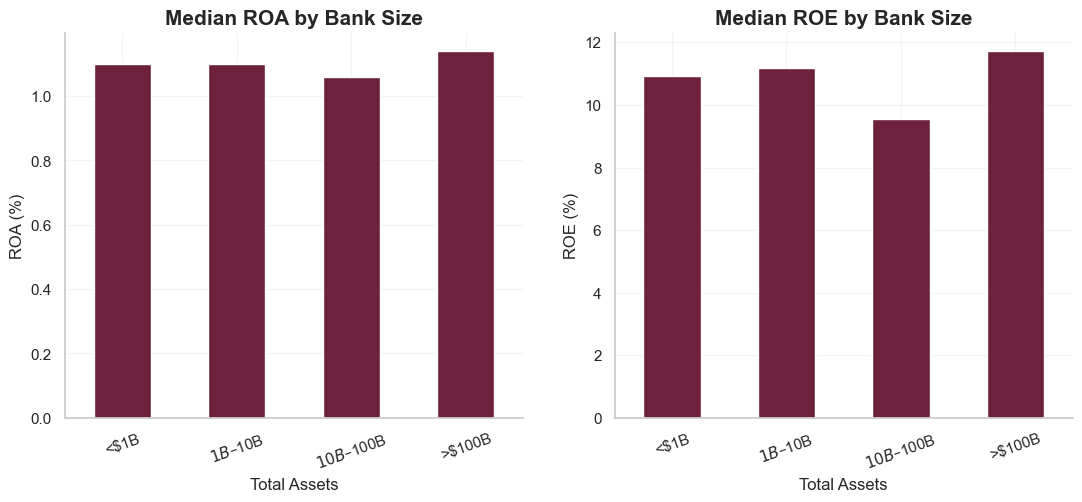

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

size_analysis["Median_ROA"].plot(
    kind="bar",
    ax=axes[0],
    title="Median ROA by Bank Size")

size_analysis["Median_ROE"].plot(
    kind="bar",
    ax=axes[1],
    title="Median ROE by Bank Size")

axes[0].set_ylabel("ROA (%)")
axes[1].set_ylabel("ROE (%)")

for ax in axes:
    ax.set_xlabel("Total Assets")
    ax.tick_params(axis="x", rotation=20)

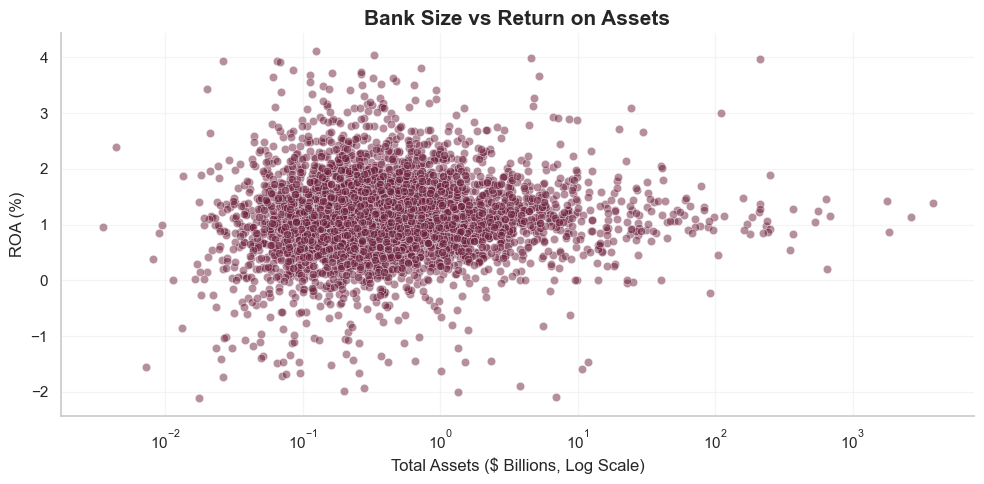

In [19]:
plot_df = df[(df["ASSET"] > 0) &df["ROA"].notna()].copy()
lower, upper = plot_df["ROA"].quantile([0.01, 0.99])

plot_df = plot_df[plot_df["ROA"].between(lower, upper)]
plt.figure(figsize=(10, 5))

sns.scatterplot(data=plot_df,x="ASSETS_B",y="ROA",alpha=0.5)

plt.xscale("log")
plt.title("Bank Size vs Return on Assets")
plt.xlabel("Total Assets ($ Billions, Log Scale)")
plt.ylabel("ROA (%)")
plt.tight_layout()
plt.show()

In [20]:
correlation = df[["ASSETS_B", "ROA", "ROE", "NIMY"]].corr(method="spearman")

display(correlation.round(3))

,ASSETS_B,ROA,ROE,NIMY
ASSETS_B,1.000,0.072,0.118,-0.133
ROA,0.072,1.000,0.843,0.538
ROE,0.118,0.843,1.000,0.404
NIMY,-0.133,0.538,0.404,1.000


In [21]:
risk_cols = ["LNLSDEPR", "RBCRWAJ"]

display( df[risk_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2).T)

,count,mean,std,min,1%,25%,50%,75%,99%,max
LNLSDEPR,4388.0,77.34,23.17,0.0,6.64,65.47,79.76,90.97,125.71,531.46
RBCRWAJ,4388.0,12.46,24.00,0.0,0.00,0.00,12.93,16.53,62.01,508.43


In [22]:
print("Zero capital ratios:", (df["RBCRWAJ"] == 0).sum())
print("Negative capital ratios:", (df["RBCRWAJ"] < 0).sum())
print("Zero deposits:", (df["DEP"] == 0).sum())

Zero capital ratios: 1720
Negative capital ratios: 0
Zero deposits: 3


In [23]:
zero_capital = df[df["RBCRWAJ"] == 0]

display(zero_capital[["NAME", "ASSET", "DEP", "ROA", "RBCRWAJ"]].head(15))

,NAME,ASSET,DEP,ROA,RBCRWAJ
3,PHENIX-GIRARD BANK,327235,309387,0.903777,0.0
4,BANK OF EVERGREEN,76420,67362,0.654286,0.0
5,COMMUNITY SPIRIT BANK,215277,194843,1.723833,0.0
6,BANK OF VERNON,401263,332846,1.541143,0.0
7,CITIZENS BANK OF WINFIELD,281554,217228,0.473298,0.0
8,EXCHANGE BANK OF ALABAMA,387699,335002,1.105452,0.0
10,PEOPLES EXCHANGE BANK,95594,83806,0.613047,0.0
11,CENTRAL STATE BANK,744160,670033,2.083570,0.0
12,BANKSOUTH,209844,167072,1.426215,0.0
13,WARREN BANK&TRUST CO,144910,116041,0.331492,0.0


In [24]:
display(df.assign(Zero_Capital=df["RBCRWAJ"].eq(0)).groupby("BANK_SIZE", observed=True)["Zero_Capital"].agg(["sum", "mean"]).round(3))

,sum,mean
BANK_SIZE,,
<$1B,1529,0.459
$1B–$10B,188,0.209
$10B–$100B,3,0.024
>$100B,0,0.000


In [25]:
df["RBCRWAJ_REVIEWED"] = df["RBCRWAJ"].replace(0, np.nan)

print("Original median:", df["RBCRWAJ"].median())
print("Excluding zeros:", df["RBCRWAJ_REVIEWED"].median())

Original median: 12.928963829080907
Excluding zeros: 15.53180683628917


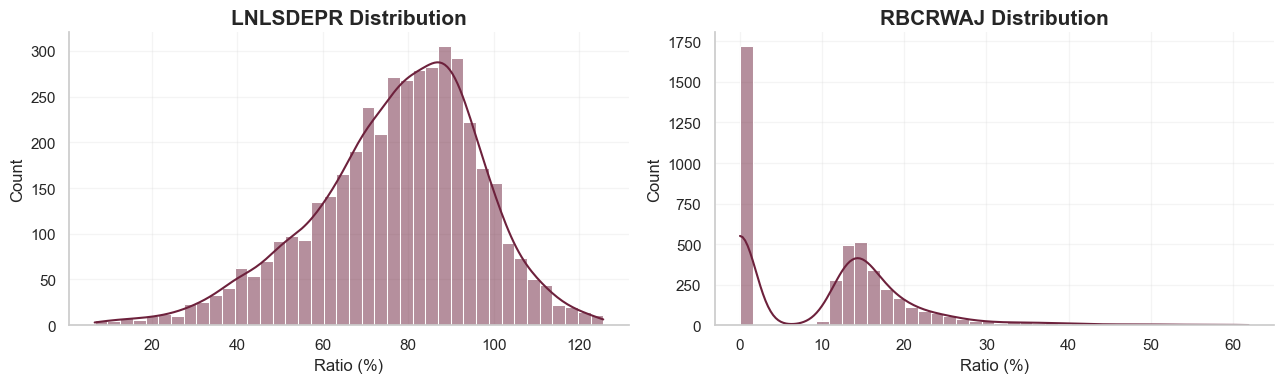

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, risk_cols):
    values = df[col].dropna()
    lower, upper = values.quantile([0.01, 0.99])

    sns.histplot(
        values[values.between(lower, upper)],
        bins=40,
        kde=True,
        ax=ax)

    ax.set_title(f"{col} Distribution")
    ax.set_xlabel("Ratio (%)")

plt.tight_layout()
plt.show()

In [27]:
risk_by_size = df.groupby("BANK_SIZE", observed=True).agg(Banks=("CERT", "count"), 
                                                          Median_Loan_Deposit=("LNLSDEPR", "median"), Median_Capital=("RBCRWAJ_REVIEWED", "median")).round(2)

display(risk_by_size)

,Banks,Median_Loan_Deposit,Median_Capital
BANK_SIZE,,,
<$1B,3331,77.16,16.45
$1B–$10B,900,86.32,14.48
$10B–$100B,127,83.10,14.49
>$100B,30,70.27,15.11


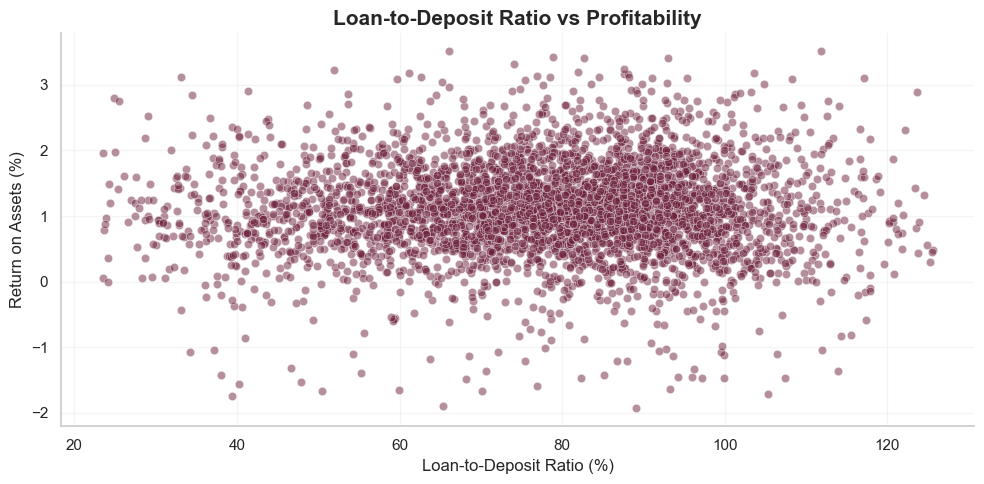

In [28]:
plot_risk = df[(df["LNLSDEPR"] > 0) &df["ROA"].notna()].copy()

x_low, x_high = plot_risk["LNLSDEPR"].quantile([0.01, 0.99])
y_low, y_high = plot_risk["ROA"].quantile([0.01, 0.99])

plot_risk = plot_risk[plot_risk["LNLSDEPR"].between(x_low, x_high) &plot_risk["ROA"].between(y_low, y_high)]

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=plot_risk,
    x="LNLSDEPR",
    y="ROA",
    alpha=0.5)

plt.title("Loan-to-Deposit Ratio vs Profitability")
plt.xlabel("Loan-to-Deposit Ratio (%)")
plt.ylabel("Return on Assets (%)")
plt.tight_layout()
plt.show()

In [31]:
df["RBCRWAJ_REVIEWED"] = df["RBCRWAJ"].replace(0, np.nan)

risk_metrics = ["ROA", "ROE", "NIMY", "LNLSDEPR", "RBCRWAJ_REVIEWED"]

corr_reviewed = df[risk_metrics].corr(method="spearman")

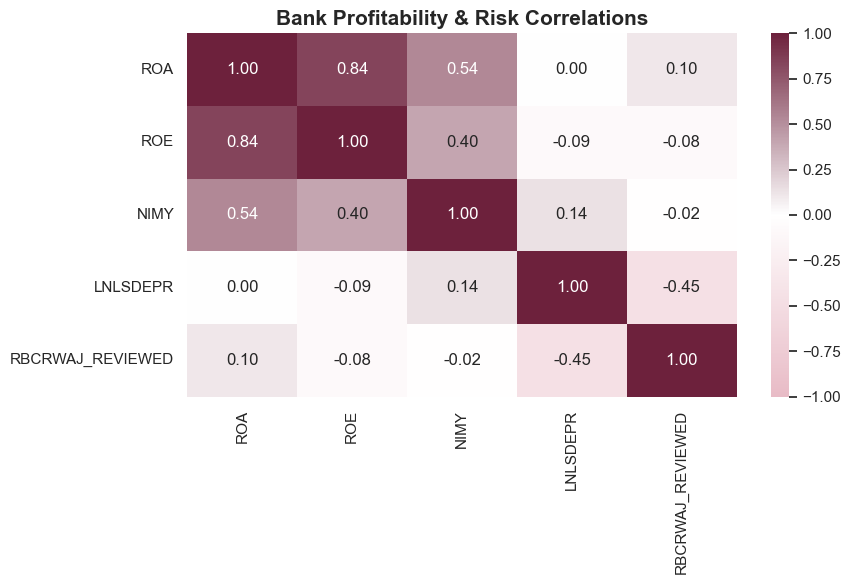

In [32]:
from matplotlib.colors import LinearSegmentedColormap

burgundy_cmap = LinearSegmentedColormap.from_list(
    "burgundy",
    ["#E8BBC6", "#FFFFFF", "#6D213C"])

plt.figure(figsize=(9, 6))

sns.heatmap(corr_reviewed, annot=True, fmt=".2f", cmap=burgundy_cmap, center=0, vmin=-1, vmax=1)

plt.title("Bank Profitability & Risk Correlations")
plt.tight_layout()
plt.show()

In [ ]:
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(key=abs, ascending=False))

display(pairs)

ROA       ROE         0.842878
          NIMY        0.538001
ROE       NIMY        0.404248
NIMY      LNLSDEPR    0.138017
LNLSDEPR  RBCRWAJ    -0.132404
ROE       LNLSDEPR   -0.088913
NIMY      RBCRWAJ    -0.067584
ROE       RBCRWAJ     0.013949
ROA       RBCRWAJ     0.005162
          LNLSDEPR    0.002168
dtype: float64

In [ ]:
risk_metrics = ["ROA", "ROE", "NIMY", "LNLSDEPR", "RBCRWAJ_REVIEWED"]

corr_reviewed = df[risk_metrics].corr(method="spearman")

display(corr_reviewed.round(3))

,ROA,ROE,NIMY,LNLSDEPR,RBCRWAJ_REVIEWED
ROA,1.000,0.843,0.538,0.002,0.102
ROE,0.843,1.000,0.404,-0.089,-0.081
NIMY,0.538,0.404,1.000,0.138,-0.016
LNLSDEPR,0.002,-0.089,0.138,1.000,-0.451
RBCRWAJ_REVIEWED,0.102,-0.081,-0.016,-0.451,1.000


In [ ]:
summary = df.groupby("BANK_SIZE", observed=True).agg(Banks=("CERT", "count"), Median_ROA=("ROA", "median"), Median_ROE=("ROE", "median"), Median_NIM=("NIMY", "median"), 
                                                     Loan_Deposit=("LNLSDEPR", "median"), Capital_Ratio=("RBCRWAJ", "median")).round(2)

display(summary)

,Banks,Median_ROA,Median_ROE,Median_NIM,Loan_Deposit,Capital_Ratio
BANK_SIZE,,,,,,
<$1B,3331,1.10,10.94,3.75,77.16,12.05
$1B–$10B,900,1.10,11.18,3.55,86.32,13.71
$10B–$100B,127,1.06,9.54,3.36,83.10,14.41
>$100B,30,1.14,11.72,3.04,70.27,15.11


In [ ]:
print("Highest median ROA:", summary["Median_ROA"].idxmax())
print("Lowest median ROA:", summary["Median_ROA"].idxmin())
print("Highest median ROE:", summary["Median_ROE"].idxmax())
print("Highest median capital ratio:", summary["Capital_Ratio"].idxmax())

Highest median ROA: >$100B
Lowest median ROA: $10B–$100B
Highest median ROE: >$100B
Highest median capital ratio: >$100B


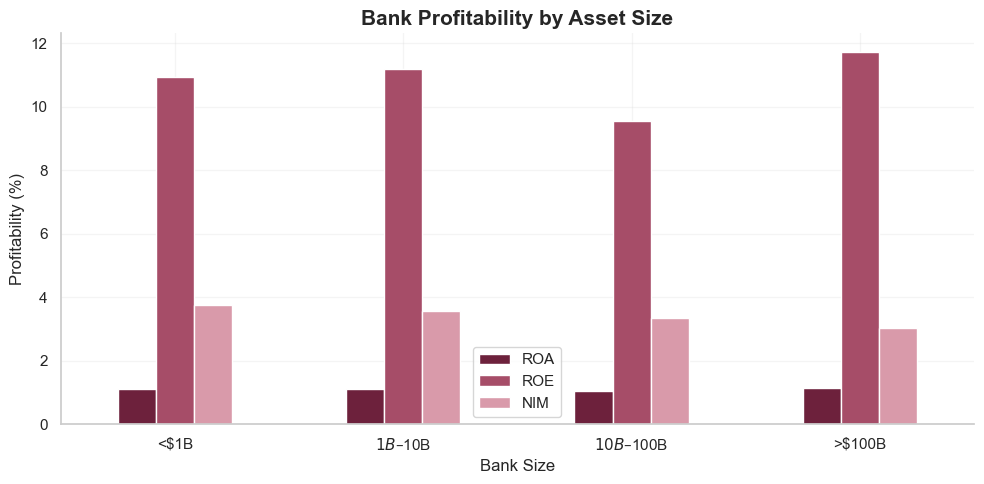

In [ ]:
comparison = summary[["Median_ROA", "Median_ROE", "Median_NIM"]]

comparison.plot(kind="bar", figsize=(10, 5))

plt.title("Bank Profitability by Asset Size")
plt.xlabel("Bank Size")
plt.ylabel("Profitability (%)")
plt.xticks(rotation=0)
plt.legend(["ROA", "ROE", "NIM"])
plt.tight_layout()
plt.show()

In [ ]:
print(f"Total banks analyzed: {len(df):,}")
print(f"Median ROA: {df['ROA'].median():.2f}%")
print(f"Median ROE: {df['ROE'].median():.2f}%")
print(f"Median NIM: {df['NIMY'].median():.2f}%")
print(f"Banks with negative ROA: {(df['ROA'] < 0).sum():,}")
print(f"Most profitable size group by median ROA: {summary['Median_ROA'].idxmax()}")

Total banks analyzed: 4,388
Median ROA: 1.10%
Median ROE: 10.96%
Median NIM: 3.67%
Banks with negative ROA: 227
Most profitable size group by median ROA: >$100B
